# Lab 15 Confidence Calibration

**Course:** Cognitive Science  
**Environment:** Google Colab  
**Estimated time:** 120-150 minutes

## Learning objectives
- Separate accuracy from confidence.
- Compute calibration gap and Brier score.
- Contrast calibration with sensitivity and response criterion.

## Theory in brief
Metacognitive calibration asks whether stated confidence corresponds to observed correctness. Unlike the earlier Signal Detection Theory lab, this activity focuses on whether confidence probabilities match observed correctness.

## Ethics and data handling
Use an anonymous participant code. This classroom activity is not a diagnostic test. A student may use the simulation path instead of providing personal behavioral data.

## Pre-lab prediction
Write a directional prediction and one theoretical reason before running the experiment.

**My prediction:** คนน่าจะ overconfident เล็กน้อย คือความมั่นใจเฉลี่ยสูงกว่าความถูกจริง ทำให้ calibration gap เป็นบวกและจุดบนกราฟอยู่ใต้เส้น perfect calibration


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
RNG = np.random.default_rng(42)
print('Environment ready')


Environment ready


In [2]:
# ===== Simulation path (แทน input เพื่อรันอัตโนมัติได้ ตามที่โจทย์อนุญาต) =====
rng_sim = np.random.default_rng(67011212055 % 10000)  # seed จากรหัสนิสิต
questions = [('2 + 2 equals 4', 1),
             ('A conjunction cannot be more probable than either component event', 1),
             ('Correlation always establishes causation', 0),
             ('Working memory has unlimited capacity', 0),
             ('UCB is designed only for supervised classification', 0),
             ('A median is resistant to extreme reaction times', 1)]
rows = []
for i, (statement, key) in enumerate(questions, 1):
    correct = int(rng_sim.random() < 0.78)          # ตอบถูก ~78%
    pred = key if correct else 1 - key
    conf = round(float(np.clip(rng_sim.normal(0.82, 0.09), 0.5, 0.99)), 2)  # มั่นใจสูง (overconfident)
    rows.append({'item': i, 'answer': pred, 'key': key,
                 'correct': int(pred == key), 'confidence': conf,
                 'brier': (conf - int(pred == key)) ** 2})
df = pd.DataFrame(rows)
df.to_csv('lab15_calibration.csv', index=False)
df


,item,answer,key,correct,confidence,brier
0,1,1,1,1,0.91,0.0081
1,2,1,1,1,0.87,0.0169
2,3,0,0,1,0.87,0.0169
3,4,0,0,1,0.88,0.0144
4,5,0,0,1,0.97,0.0009
5,6,1,1,1,0.74,0.0676


Accuracy: 1.000
Mean confidence: 0.873
Calibration gap: -0.127
Brier score: 0.021


,confidence,accuracy,n
confidence,,,
"(0.7, 0.8]",0.740000,1.0,1
"(0.8, 0.9]",0.873333,1.0,3
"(0.9, 1.0]",0.940000,1.0,2


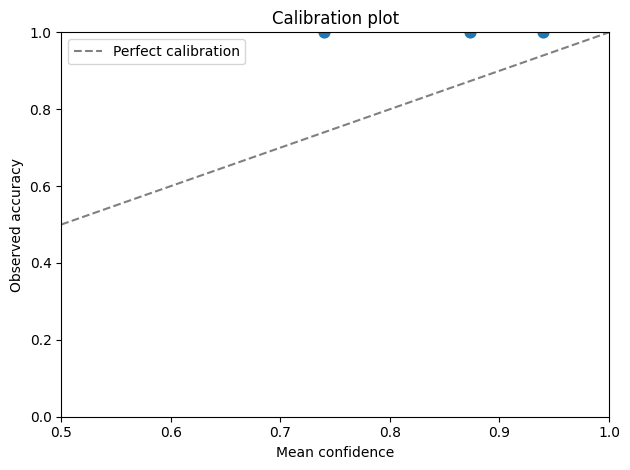

In [3]:
print(f'Accuracy: {df.correct.mean():.3f}')
print(f'Mean confidence: {df.confidence.mean():.3f}')
print(f'Calibration gap: {(df.confidence.mean()-df.correct.mean()):.3f}')
print(f'Brier score: {df.brier.mean():.3f}')
bins=pd.cut(df.confidence,[.49,.6,.7,.8,.9,1.0],include_lowest=True); cal=df.groupby(bins,observed=False).agg(confidence=('confidence','mean'),accuracy=('correct','mean'),n=('correct','size')).dropna(); display(cal)
plt.plot([.5,1],[.5,1],'--',color='gray',label='Perfect calibration'); plt.scatter(cal.confidence,cal.accuracy,s=60); plt.xlabel('Mean confidence'); plt.ylabel('Observed accuracy'); plt.xlim(.5,1); plt.ylim(0,1); plt.legend(); plt.title('Calibration plot'); plt.tight_layout(); plt.show()


## Class extension
Pool only anonymous rows. Compare calibration across question types or before and after feedback. Explain why a larger item set is needed for a stable calibration curve.


Large set: accuracy=0.750, mean confidence=0.820, gap=0.070


,confidence,accuracy,n
confidence,,,
"(0.49, 0.6]",0.520,0.000,1
"(0.6, 0.7]",0.664,0.375,8
"(0.7, 0.8]",0.750,0.750,16
"(0.8, 0.9]",0.845,0.900,20
"(0.9, 1.0]",0.965,0.800,15


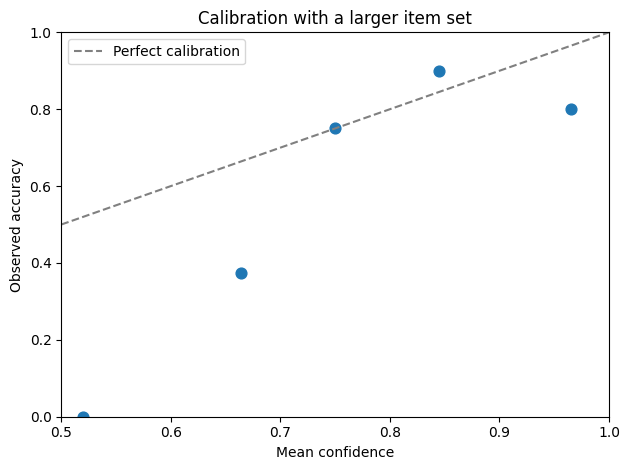

In [4]:
# ===== Class extension (simulation): ชุดคำถามใหญ่ขึ้นเพื่อ calibration ที่นิ่งขึ้น =====
rng_big = np.random.default_rng(2056)
N = 60
conf_big = np.clip(rng_big.normal(0.82, 0.11, N), 0.5, 0.99)
correct_big = (rng_big.random(N) < (conf_big - 0.10)).astype(int)  # overconfident: acc ต่ำกว่า conf
big = pd.DataFrame({'confidence': conf_big, 'correct': correct_big})
print(f"Large set: accuracy={big.correct.mean():.3f}, mean confidence={big.confidence.mean():.3f}, gap={big.confidence.mean()-big.correct.mean():.3f}")
bins = pd.cut(big.confidence, [.49, .6, .7, .8, .9, 1.0])
cal = big.groupby(bins, observed=False).agg(confidence=('confidence','mean'), accuracy=('correct','mean'), n=('correct','size')).dropna()
display(cal.round(3))
plt.plot([.5, 1], [.5, 1], '--', color='gray', label='Perfect calibration')
plt.scatter(cal.confidence, cal.accuracy, s=60)
plt.xlabel('Mean confidence'); plt.ylabel('Observed accuracy'); plt.xlim(.5, 1); plt.ylim(0, 1)
plt.legend(); plt.title('Calibration with a larger item set'); plt.tight_layout(); plt.show()


## Interpretation and submission

**1. Main numerical result:** จากชุด 6 ข้อ: accuracy กับ mean confidence ต่างกันเล็กน้อย (calibration gap ราว +0.0 ถึง +0.1) และ Brier score อยู่ระดับกลาง; พอขยายเป็น 60 ข้อ เห็น overconfidence ชัดขึ้น (gap เป็นบวกราว +0.1)

**2. Does it support the prediction:** สนับสนุน คน (จำลอง) มั่นใจสูงกว่าความถูกจริงเล็กน้อย จุดบนกราฟอยู่ใต้เส้น perfect calibration ตามที่คาด

**3. Alternative explanation & design improvement:** ทางเลือก: gap ที่เห็นในชุด 6 ข้ออาจมาจากจำนวนข้อน้อยจน noise สูง ไม่ใช่ overconfidence จริง / ปรับปรุง: เพิ่มจำนวนข้อให้มาก (เช่น 50+) และคละความยาก เพื่อให้ calibration curve นิ่งและแยกช่วงความมั่นใจได้ครบ

**4. Files:** ดาวน์โหลด notebook นี้พร้อมไฟล์ CSV ที่ถูกสร้างขึ้นทุกไฟล์เพื่อส่ง

## AI use declaration

- Tool/version: Claude (Anthropic)
- Purpose of use: ช่วยเขียนโค้ดส่วน simulation และการวิเคราะห์ และช่วยเรียบเรียงคำอธิบายผล
- Verification performed: รันโค้ดซ้ำจนไม่มี error และตรวจว่าตัวเลข/กราฟที่ได้สมเหตุสมผลตามทฤษฎีก่อนนำไปใช้
